##EDA Project: House Pricing Analysis
####Name: Chaitanya Saini
####URN: E25B032633
####Section: B


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] =(10, 6)

df= pd.read_csv("/content/drive/MyDrive/Ames housing dataset/AmesHousing.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
display(missing_values)
missing_percentage = (missing_values / len(df)) *100

print("\nMissing Value Percentage:")
display(missing_percentage)

Dataset Shape: (2930, 82)

First 5 Rows:


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   objec

,0
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Cond,159
Garage Yr Blt,159



Missing Value Percentage:


,0
Pool QC,99.556314
Misc Feature,96.382253
Alley,93.242321
Fence,80.477816
Mas Vnr Type,60.580205
Fireplace Qu,48.532423
Lot Frontage,16.723549
Garage Qual,5.426621
Garage Cond,5.426621
Garage Yr Blt,5.426621


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))

ordinal_map = {
    col: ["Po", "Fa", "TA", "Gd", "Ex"]
    for col in ["ExterQual", "KitchenQual"]
    if col in df.columns
}

for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )
summary = []

for column in df.columns:
    if column in ordinal_map or column == "OverallQual":
        variable_type = "Ordinal"
    elif column in numeric_cols:
        variable_type = "Numerical"
    else:
        variable_type = "Categorical"

    summary.append({
        "Column Name": column,
        "Type": variable_type,
        "Unique Values": df[column].nunique(),
        "Example Values": df[column].dropna().unique()[:5].tolist()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


Numerical Columns: 39
Categorical Columns: 43


,Column Name,Type,Unique Values,Example Values
0,Order,Numerical,2930,"[1, 2, 3, 4, 5]"
1,PID,Numerical,2930,"[526301100, 526350040, 526351010, 526353030, 5..."
2,MS SubClass,Numerical,16,"[20, 60, 120, 50, 85]"
3,MS Zoning,Categorical,7,"[RL, RH, FV, RM, C (all)]"
4,Lot Frontage,Numerical,128,"[141.0, 80.0, 81.0, 93.0, 74.0]"
...,...,...,...,...
77,Mo Sold,Numerical,12,"[5, 6, 4, 3, 1]"
78,Yr Sold,Numerical,5,"[2010, 2009, 2008, 2007, 2006]"
79,Sale Type,Categorical,10,"[WD , New, COD, ConLI, Con]"
80,Sale Condition,Categorical,6,"[Normal, Partial, Family, Abnorml, Alloca]"


In [ ]:
df.describe()
columns = ["SalePrice", "Gr Liv Area", "Lot Area"]

for column in columns:
    print(f"\nStatistics for {column}")
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Mode:", df[column].mode().iloc[0])
    print("Standard Deviation:", df[column].std())
    print("Variance:", df[column].var())
    print("Range:", df[column].max() - df[column].min())
    print("IQR:", df[column].quantile(0.75) - df[column].quantile(0.25))
    print("Skewness:", df[column].skew())
    print("Kurtosis:", df[column].kurtosis())

    if df[column].mean() > df[column].median():
        print("Distribution: Right Skewed")
    elif df[column].mean() < df[column].median():
        print("Distribution: Left Skewed")
    else:
        print("Distribution: Approximately Symmetrical")
for column in ["Neighborhood", "House Style"]:
    print(f"\nValue Counts for {column}:")
    print(df[column].value_counts())

    print("Mode:", df[column].mode().tolist())


Statistics for SalePrice
Mean: 180796.0600682594
Median: 160000.0
Mode: 135000
Standard Deviation: 79886.69235666493
Variance: 6381883615.688427
Range: 742211
IQR: 84000.0
Skewness: 1.7435000757376466
Kurtosis: 5.118899951130896
Distribution: Right Skewed

Statistics for Gr Liv Area
Mean: 1499.6904436860068
Median: 1442.0
Mode: 864
Standard Deviation: 505.5088874720413
Variance: 255539.2353132209
Range: 5308
IQR: 616.75
Skewness: 1.2741097164955077
Kurtosis: 4.137838193203049
Distribution: Right Skewed

Statistics for Lot Area
Mean: 10147.921843003413
Median: 9436.5
Mode: 9600
Standard Deviation: 7880.017759439081
Variance: 62094679.88907532
Range: 213945
IQR: 4115.0
Skewness: 12.820898171092681
Kurtosis: 265.0236706029328
Distribution: Right Skewed

Value Counts for Neighborhood:
Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
NridgHt    166
Gilbert    165
Sawyer     151
NWAmes     131
SawyerW    125
Mitchel    114
BrkSide    108
Crawfor    103

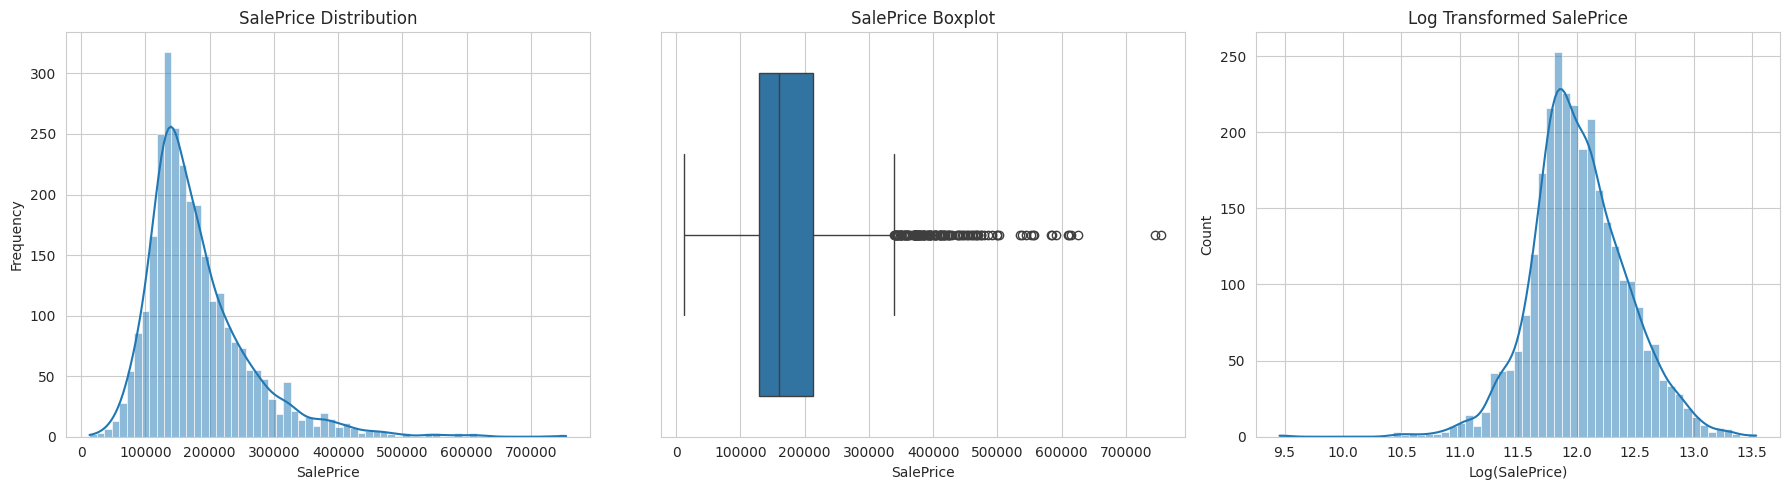

Original Skewness: 1.7435000757376466
Log Transformed Skewness: -0.014793439509736364


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")
axes[2].set_xlabel("Log(SalePrice)")

plt.tight_layout()
plt.show()

print("Original Skewness:", df["SalePrice"].skew())
print("Log Transformed Skewness:", np.log(df["SalePrice"]).skew())

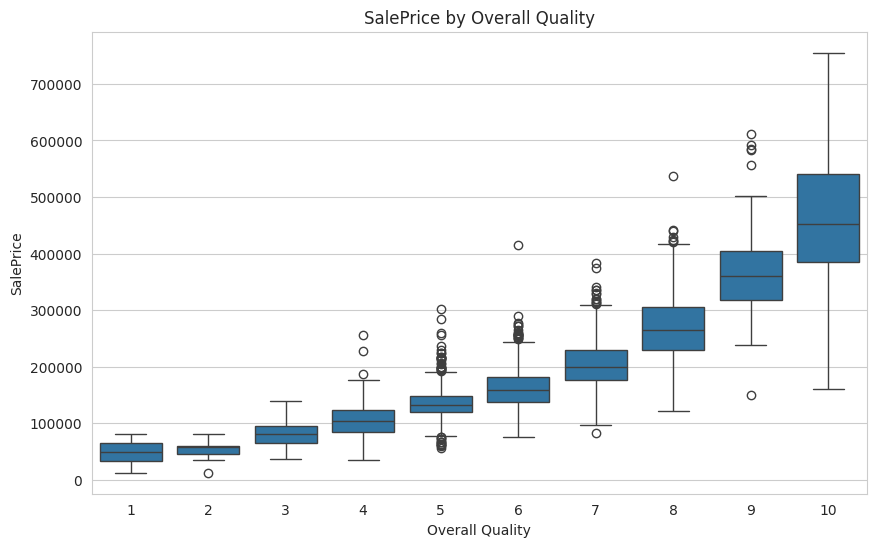

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="Overall Qual", y="SalePrice", data=df)
plt.title("SalePrice by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("SalePrice")
plt.show()

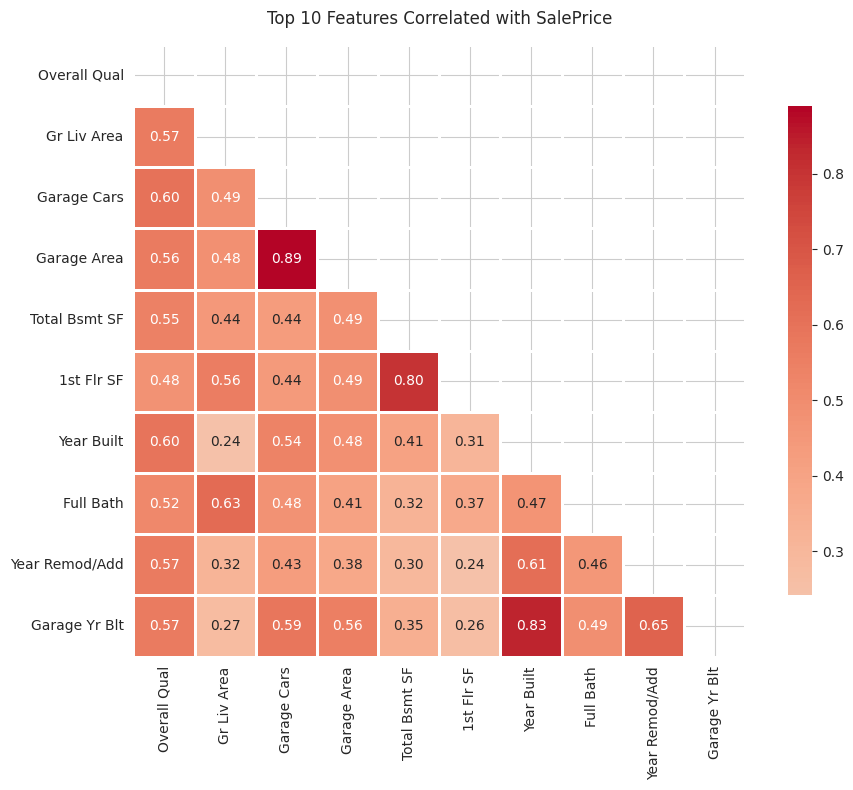

In [ ]:
top10 = corr_matrix["SalePrice"].abs().sort_values(ascending=False).head(11).index.drop("SalePrice")

corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8}
)

plt.title("Top 10 Features Correlated with SalePrice", pad=15)
plt.tight_layout()
plt.show()

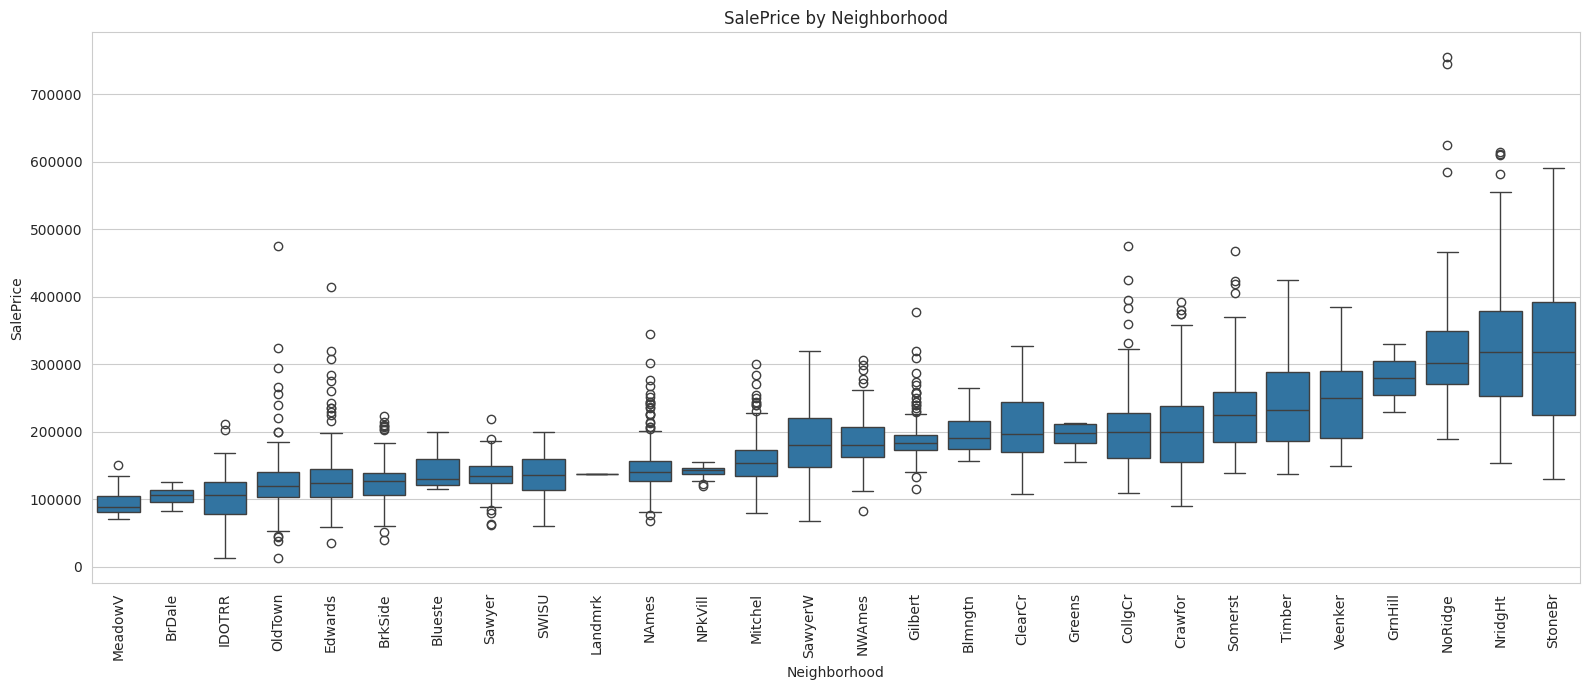

In [ ]:
neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(16, 7))
sns.boxplot(
    x="Neighborhood",
    y="SalePrice",
    data=df,
    order=neighborhood_order
)

plt.title("SalePrice by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

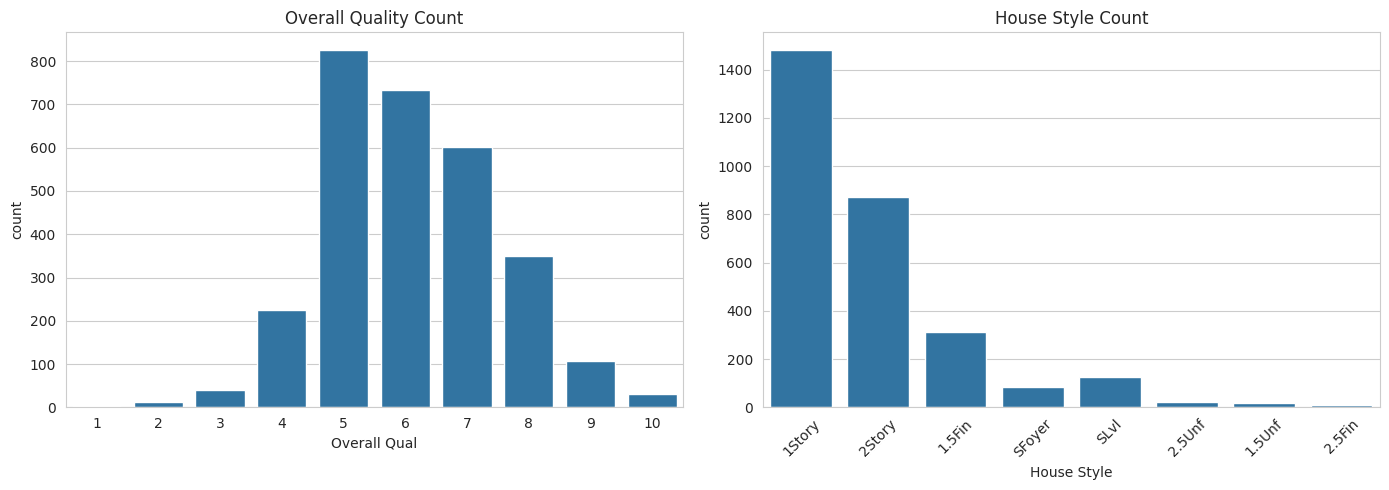

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="Overall Qual", data=df, ax=axes[0])
axes[0].set_title("Overall Quality Count")

sns.countplot(x="House Style", data=df, ax=axes[1])
axes[1].set_title("House Style Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
cov_matrix = df.select_dtypes(include=np.number).cov()

corr_matrix = df.select_dtypes(include=np.number).corr(method="pearson")
top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)

print("Top 10 Features Correlated with SalePrice:")
print(top_corr.head(11))
top_3_features = top_corr.drop("SalePrice").head(3).index

print("\nCovariance and Correlation with SalePrice:")
for column in top_3_features:
    print(f"\nFeature: {column}")
    print("Covariance:", cov_matrix.loc[column, "SalePrice"])
    print("Correlation:", corr_matrix.loc[column, "SalePrice"])

ordinal_cols = ["Overall Qual", "Overall Cond", "Exter Qual", "Kitchen Qual"]

available_ordinal_cols = [col for col in ordinal_cols if col in df.columns]
ordinal_data = df[available_ordinal_cols + ["SalePrice"]].copy()

for col in available_ordinal_cols:
    if not pd.api.types.is_numeric_dtype(ordinal_data[col]):
        ordinal_data[col] = ordinal_data[col].astype("category").cat.codes

spearman_corr = ordinal_data.corr(method="spearman")
print("\nSpearman Correlation with SalePrice:")
print(spearman_corr["SalePrice"].sort_values(ascending=False))

Top 10 Features Correlated with SalePrice:
SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Name: SalePrice, dtype: float64

Covariance and Correlation with SalePrice:

Feature: Overall Qual
Covariance: 90094.55319256545
Correlation: 0.7992617947690243

Feature: Gr Liv Area
Covariance: 28542199.568276495
Correlation: 0.7067799209766268

Feature: Garage Cars
Covariance: 39370.19953972153
Correlation: 0.64787659539566

Spearman Correlation with SalePrice:
SalePrice       1.000000
Overall Qual    0.808800
Overall Cond   -0.165657
Kitchen Qual   -0.576162
Exter Qual     -0.626131
Name: SalePrice, dtype: float64


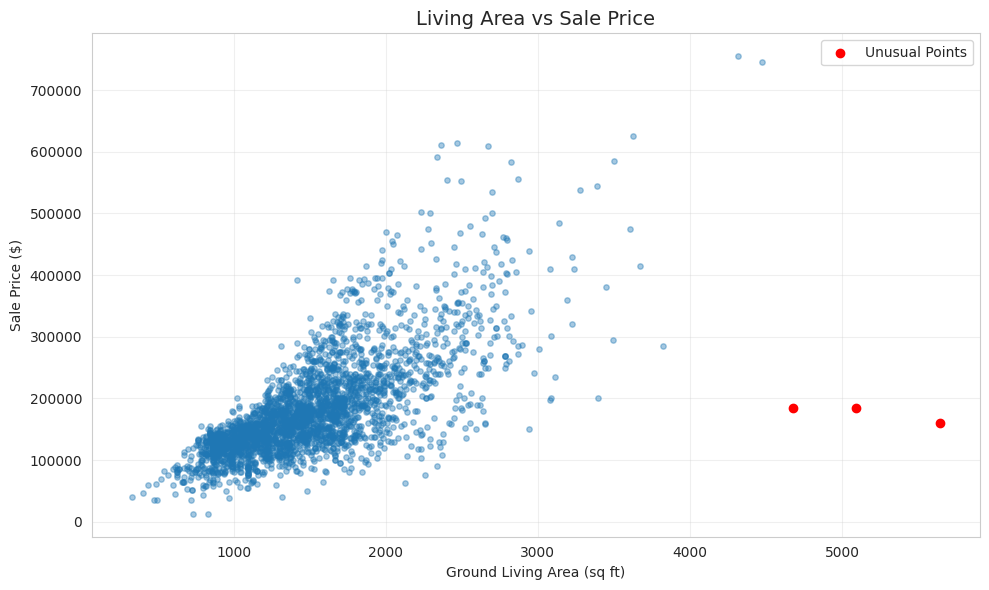

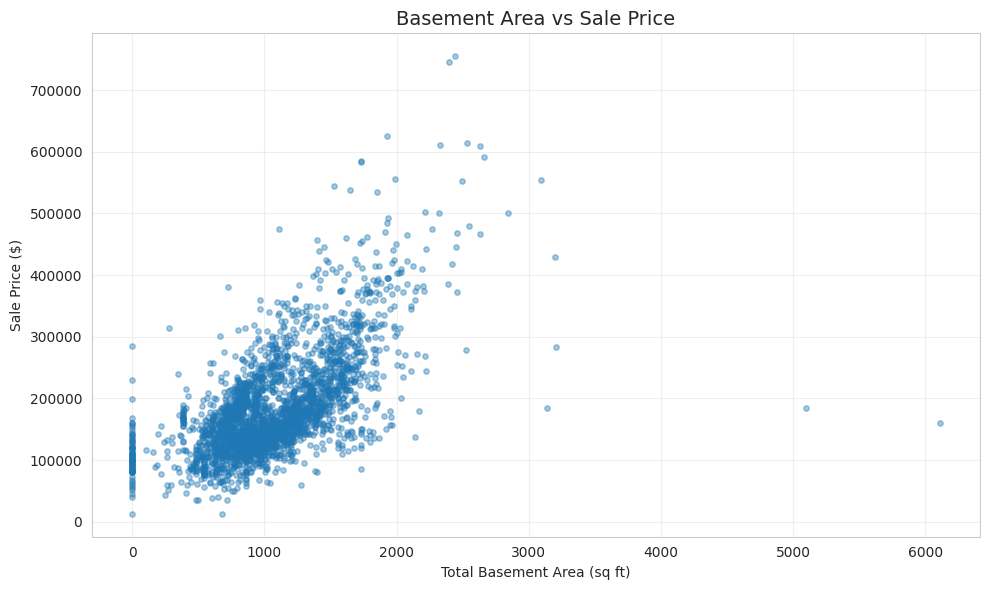

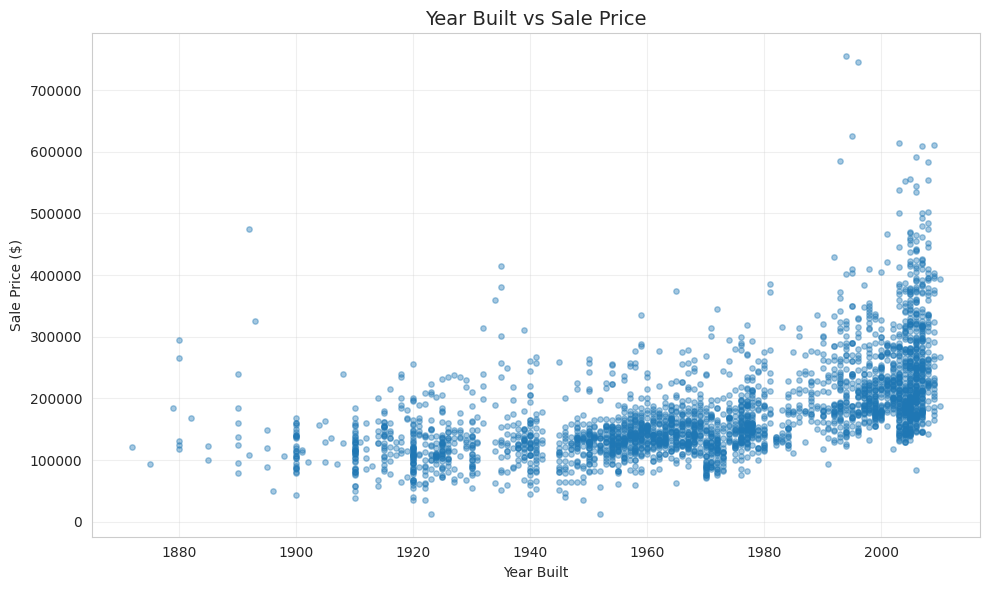

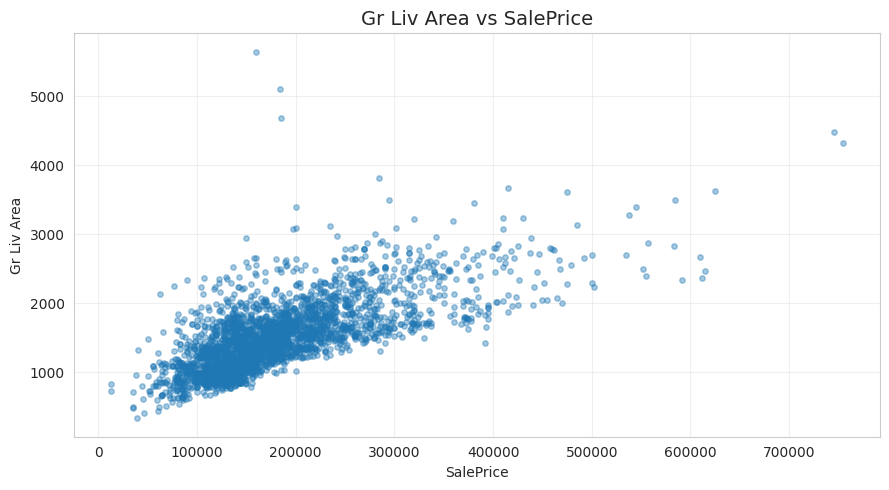

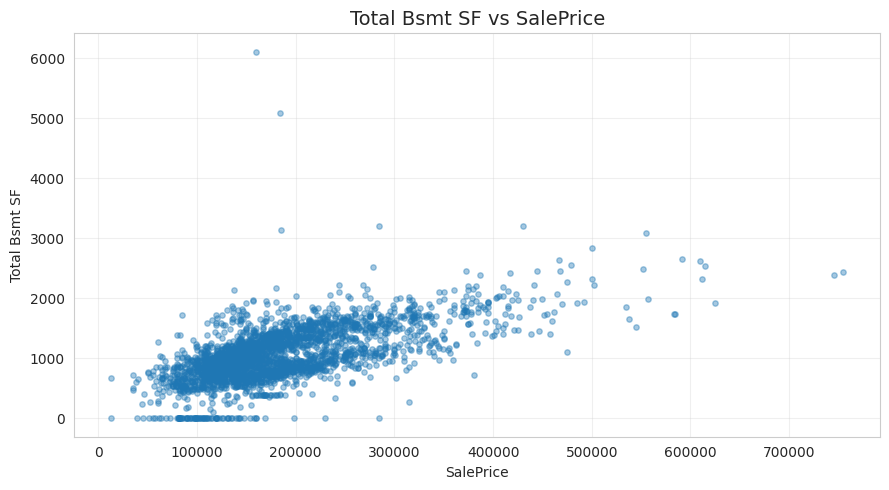

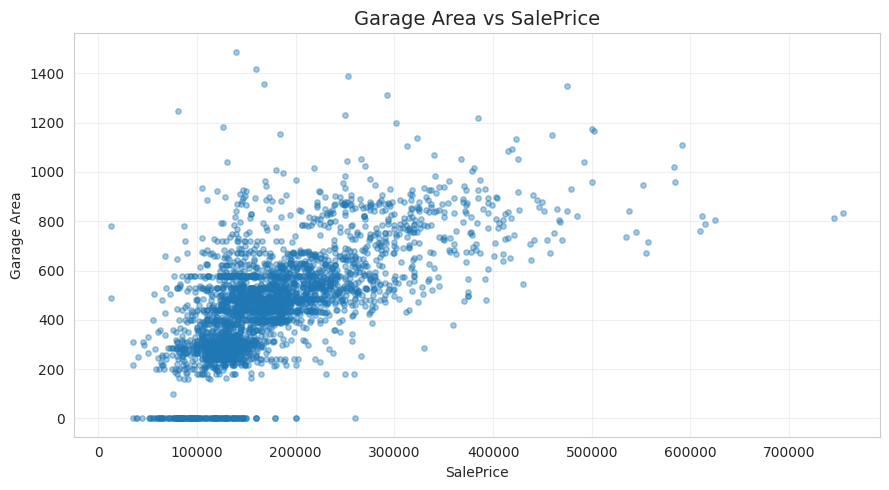

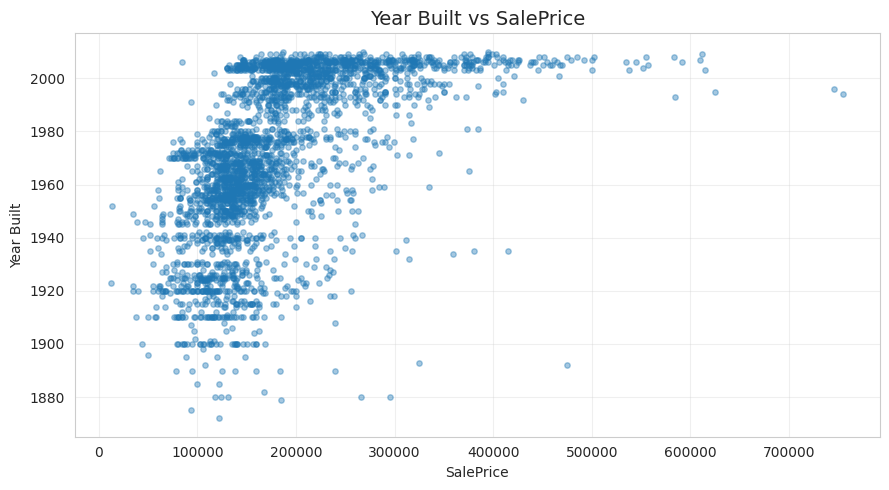

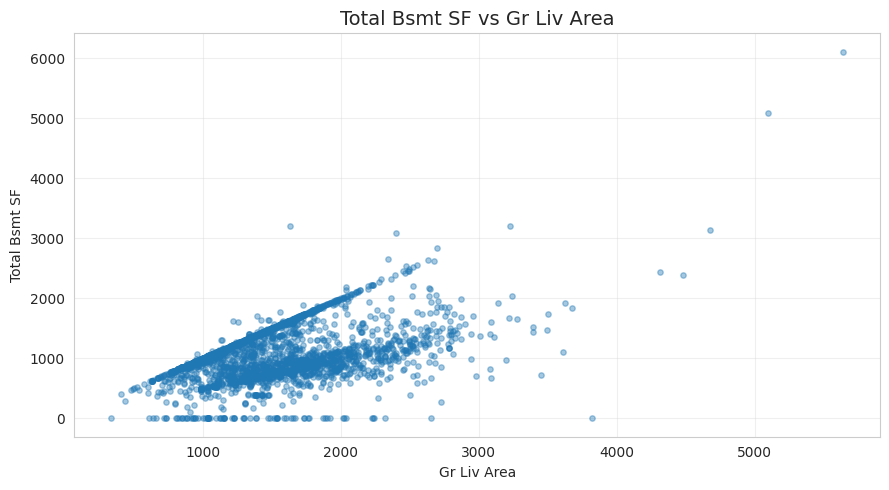

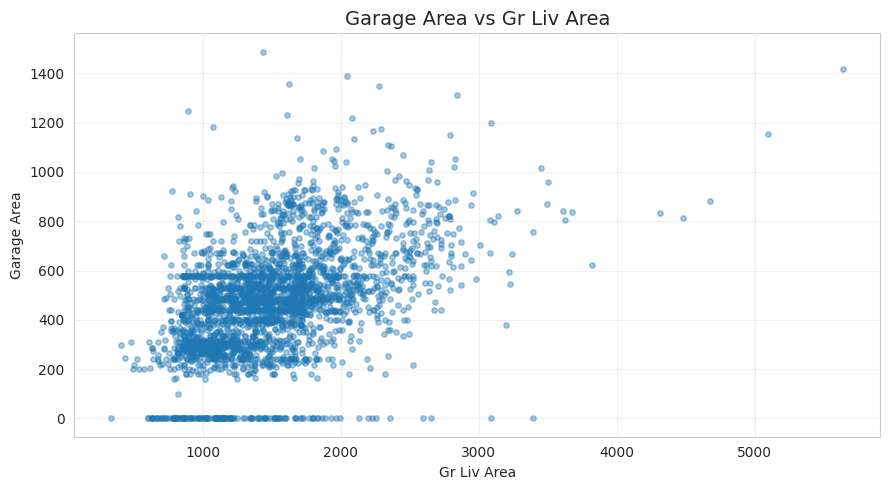

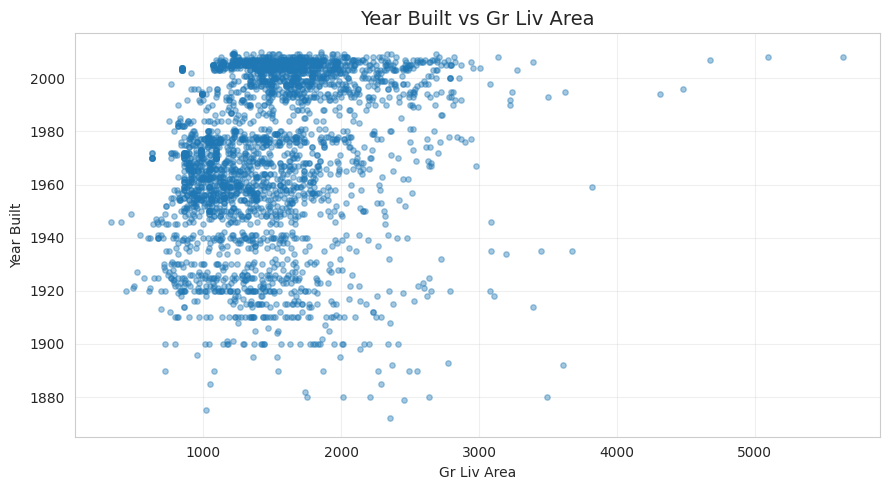

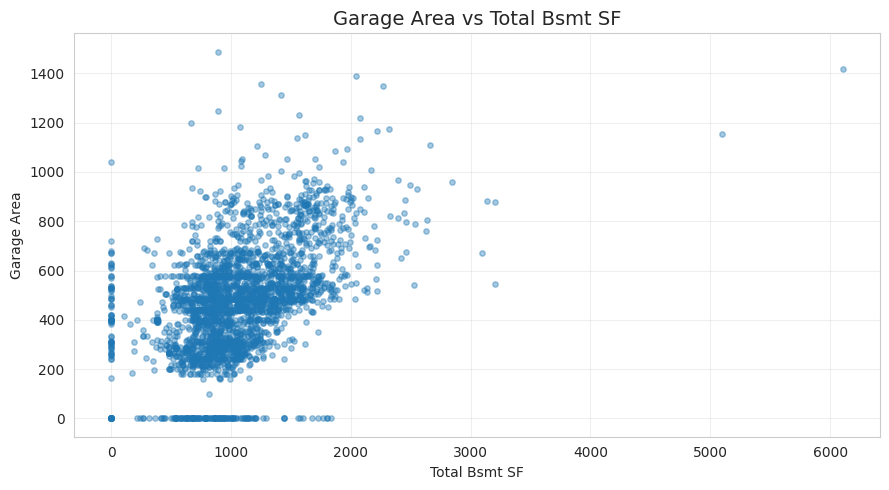

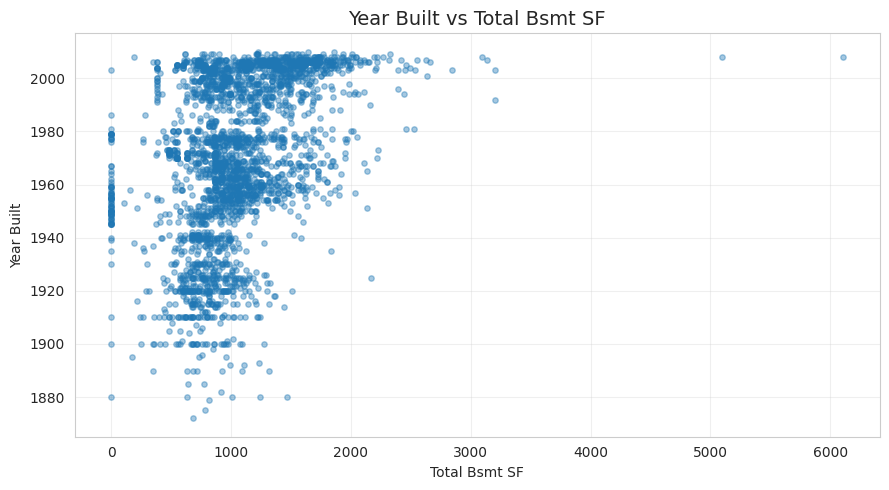

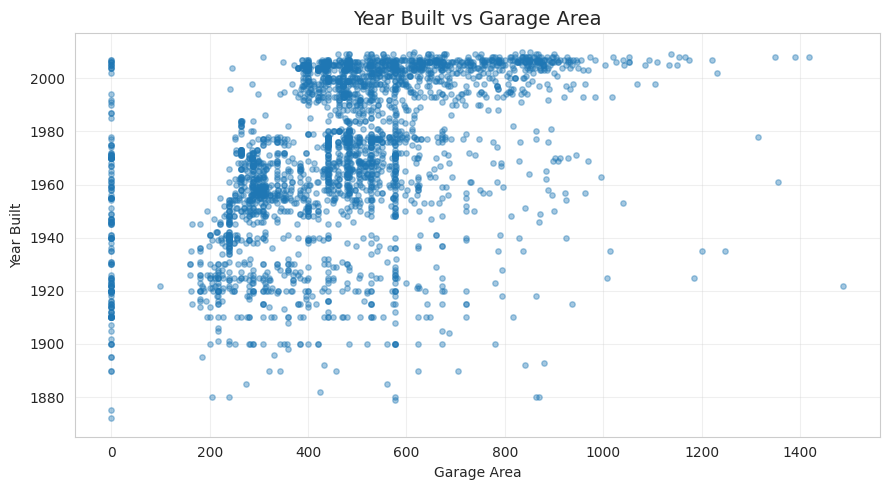

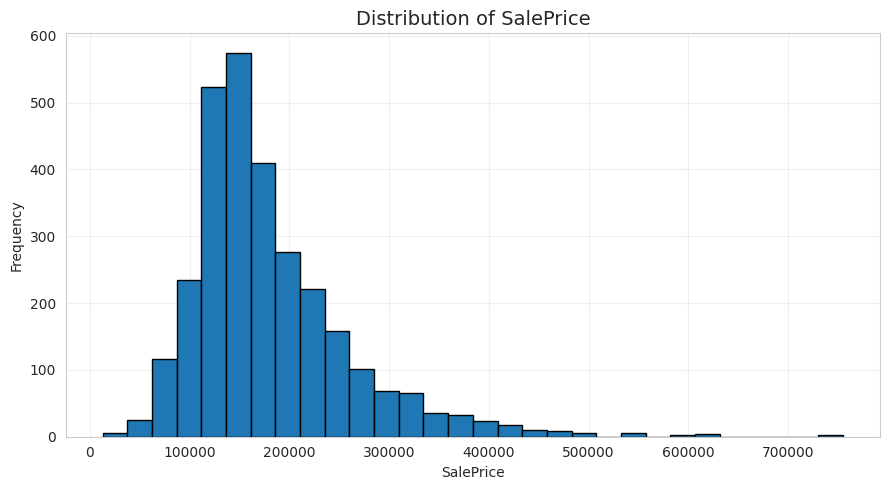

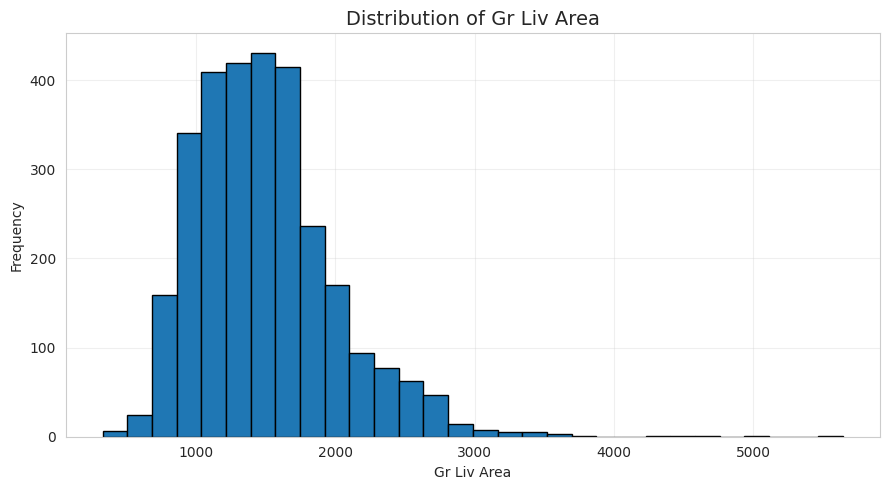

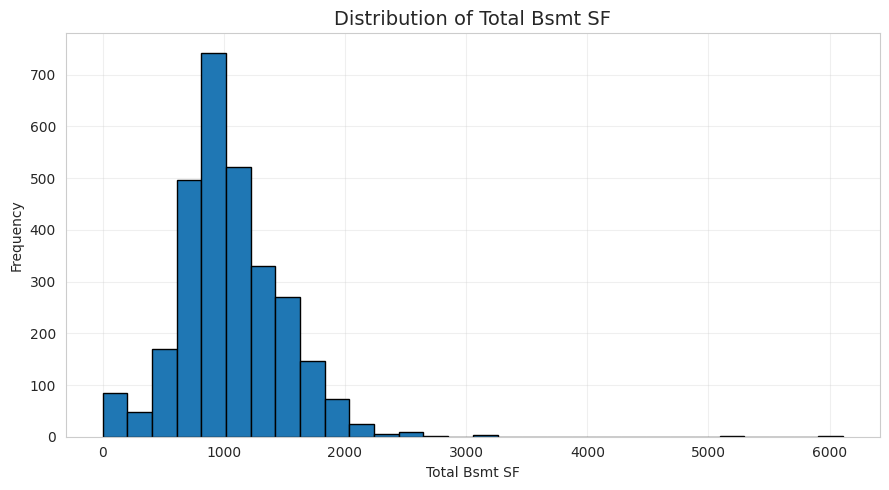

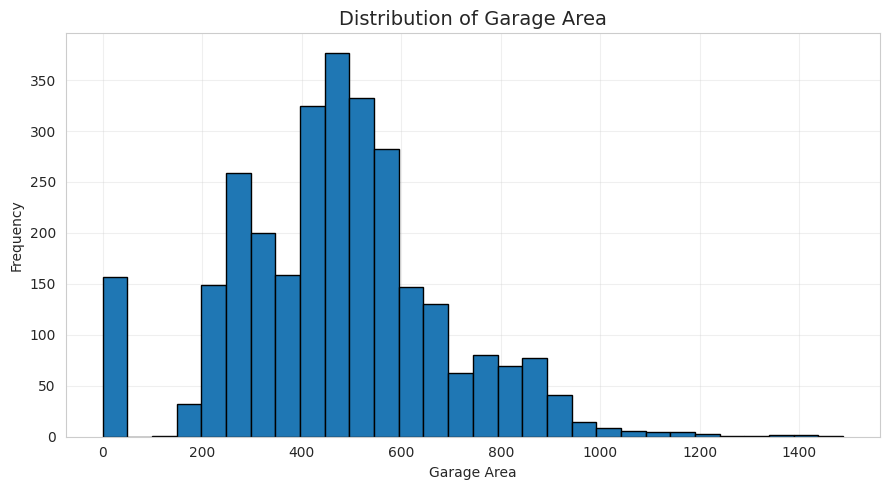

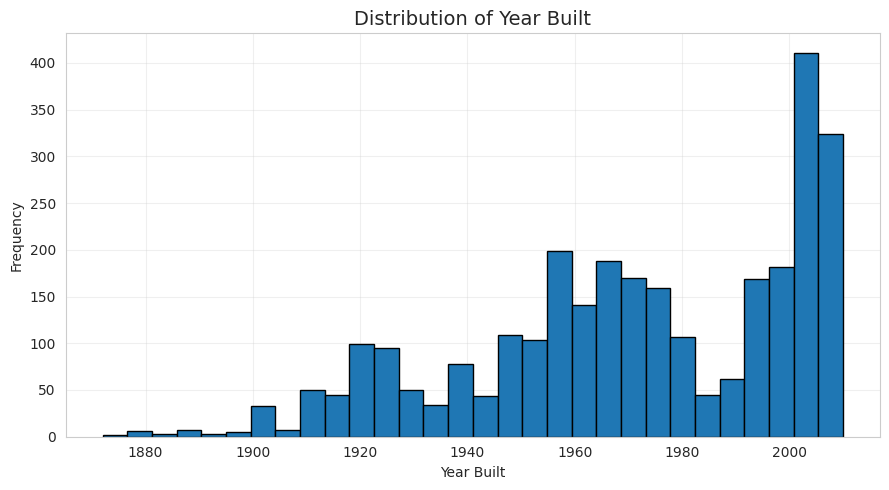

In [ ]:
plt.figure(figsize=(10, 6))

outliers = (df["Gr Liv Area"] > 4000) & (df["SalePrice"] < 200000)

plt.scatter(df["Gr Liv Area"], df["SalePrice"], alpha=0.4, s=15)
plt.scatter(df.loc[outliers, "Gr Liv Area"],
            df.loc[outliers, "SalePrice"],
            color="red", label="Unusual Points")

plt.title("Living Area vs Sale Price", fontsize=14)
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

plt.scatter(df["Total Bsmt SF"], df["SalePrice"], alpha=0.4, s=15)

plt.title("Basement Area vs Sale Price", fontsize=14)
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

plt.scatter(df["Year Built"], df["SalePrice"], alpha=0.4, s=15)

plt.title("Year Built vs Sale Price", fontsize=14)
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

selected = ["SalePrice", "Gr Liv Area", "Total Bsmt SF",
            "Garage Area", "Year Built"]

for i in range(len(selected)):
    for j in range(i + 1, len(selected)):

        x = selected[i]
        y = selected[j]

        plt.figure(figsize=(9, 5))
        plt.scatter(df[x], df[y], alpha=0.4, s=15)

        plt.title(f"{y} vs {x}", fontsize=14)
        plt.xlabel(x)
        plt.ylabel(y)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

for col in selected:
    plt.figure(figsize=(9, 5))
    plt.hist(df[col].dropna(), bins=30, edgecolor="black")

    plt.title(f"Distribution of {col}", fontsize=14)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

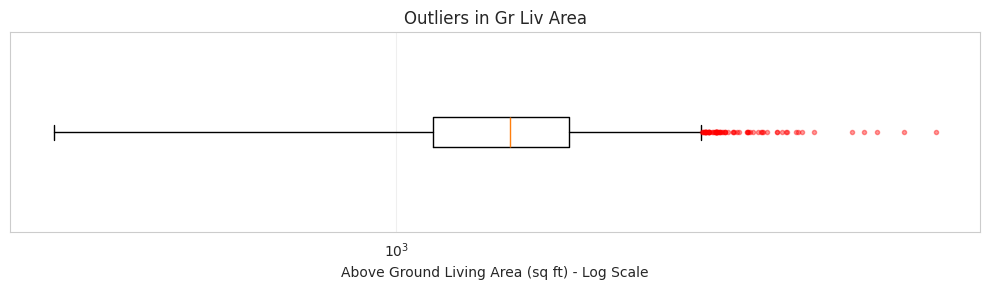

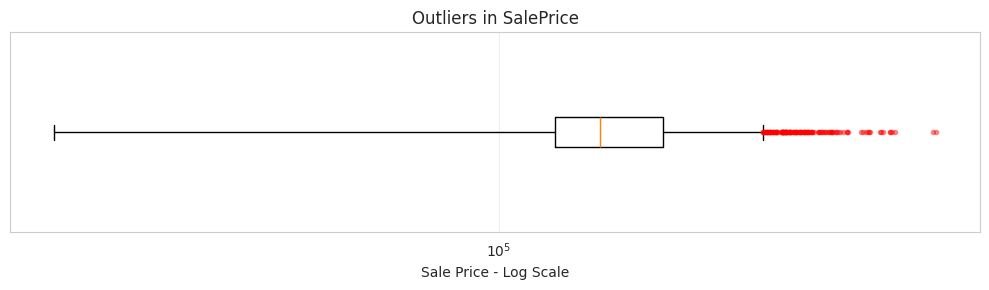

In [ ]:
from IPython.display import display, HTML

flier_style = dict(
    marker='o',
    markerfacecolor='red',
    markeredgecolor='red',
    markersize=3,
    alpha=0.4
)
plt.figure(figsize=(10, 3))
plt.boxplot(
    df['Gr Liv Area'].dropna(),
    vert=False,
    flierprops=flier_style
)

plt.xscale('log')
plt.title("Outliers in Gr Liv Area")
plt.xlabel("Above Ground Living Area (sq ft) - Log Scale")
plt.yticks([])
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

display(HTML("<div style='height:35px'></div>"))
plt.figure(figsize=(10, 3))
plt.boxplot(
    df['SalePrice'].dropna(),
    vert=False,
    flierprops=flier_style
)

plt.xscale('log')
plt.title("Outliers in SalePrice")
plt.xlabel("Sale Price - Log Scale")
plt.yticks([])
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

In [ ]:
df_clean = df.copy()
dup_count = df_clean.duplicated().sum()

print("Duplicate rows:", dup_count)

df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)
categorical_cols = df_clean.select_dtypes(
    include=['object', 'category', 'string']
).columns

for col in categorical_cols:
    values = df_clean[col].dropna().astype(str).unique()

    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

print("\nCategorical columns standardised.")


absence_cols = [
    'Pool QC', 'Alley', 'Fence', 'Fireplace Qu',
    'Garage Type', 'Garage Finish', 'Garage Qual',
    'Garage Cond', 'Bsmt Qual', 'Bsmt Cond',
    'Bsmt Exposure', 'BsmtFin Type 1',
    'BsmtFin Type 2', 'Mas Vnr Type', 'Misc Feature'
]

for col in absence_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('None')


if 'Lot Frontage' in df_clean.columns:
    df_clean['Lot Frontage'] = df_clean.groupby(
        'Neighborhood'
    )['Lot Frontage'].transform(
        lambda x: x.fillna(x.median())
    )


    df_clean['Lot Frontage'] = df_clean['Lot Frontage'].fillna(
        df_clean['Lot Frontage'].median()
    )

if 'Mas Vnr Area' in df_clean.columns:
    df_clean['Mas Vnr Area'] = df_clean['Mas Vnr Area'].fillna(0)


numeric_cols = df_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )


categorical_cols = df_clean.select_dtypes(
    include=['object', 'category', 'string']
).columns

for col in categorical_cols:
    if df_clean[col].isna().any():
        mode = df_clean[col].mode()

        if not mode.empty:
            df_clean[col] = df_clean[col].fillna(mode[0])


missing_count = df_clean.isna().sum().sum()

print("\nTotal remaining missing values:", missing_count)

if missing_count == 0:
    print("All missing values have been handled.")
else:
    print("Columns with remaining missing values:")
    print(df_clean.isna().sum()[df_clean.isna().sum() > 0])


year_errors = np.sum(
    df_clean['Year Built'] > df_clean['Yr Sold']
)

print("\nHouses built after sale year:", year_errors)

area_cols = [
    'Lot Area', 'Gr Liv Area', 'Total Bsmt SF',
    'Garage Area', '1st Flr SF', '2nd Flr SF'
]

for col in area_cols:
    if col in df_clean.columns:
        negative_count = np.sum(df_clean[col] < 0)
        print(f"Negative values in {col}: {negative_count}")


print("\nFinal cleaned dataset shape:", df_clean.shape)

Duplicate rows: 0
Shape after removing duplicates: (2930, 82)

Categorical columns standardised.

Total remaining missing values: 0
All missing values have been handled.

Houses built after sale year: 1
Negative values in Lot Area: 0
Negative values in Gr Liv Area: 0
Negative values in Total Bsmt SF: 0
Negative values in Garage Area: 0
Negative values in 1st Flr SF: 0
Negative values in 2nd Flr SF: 0

Final cleaned dataset shape: (2930, 82)


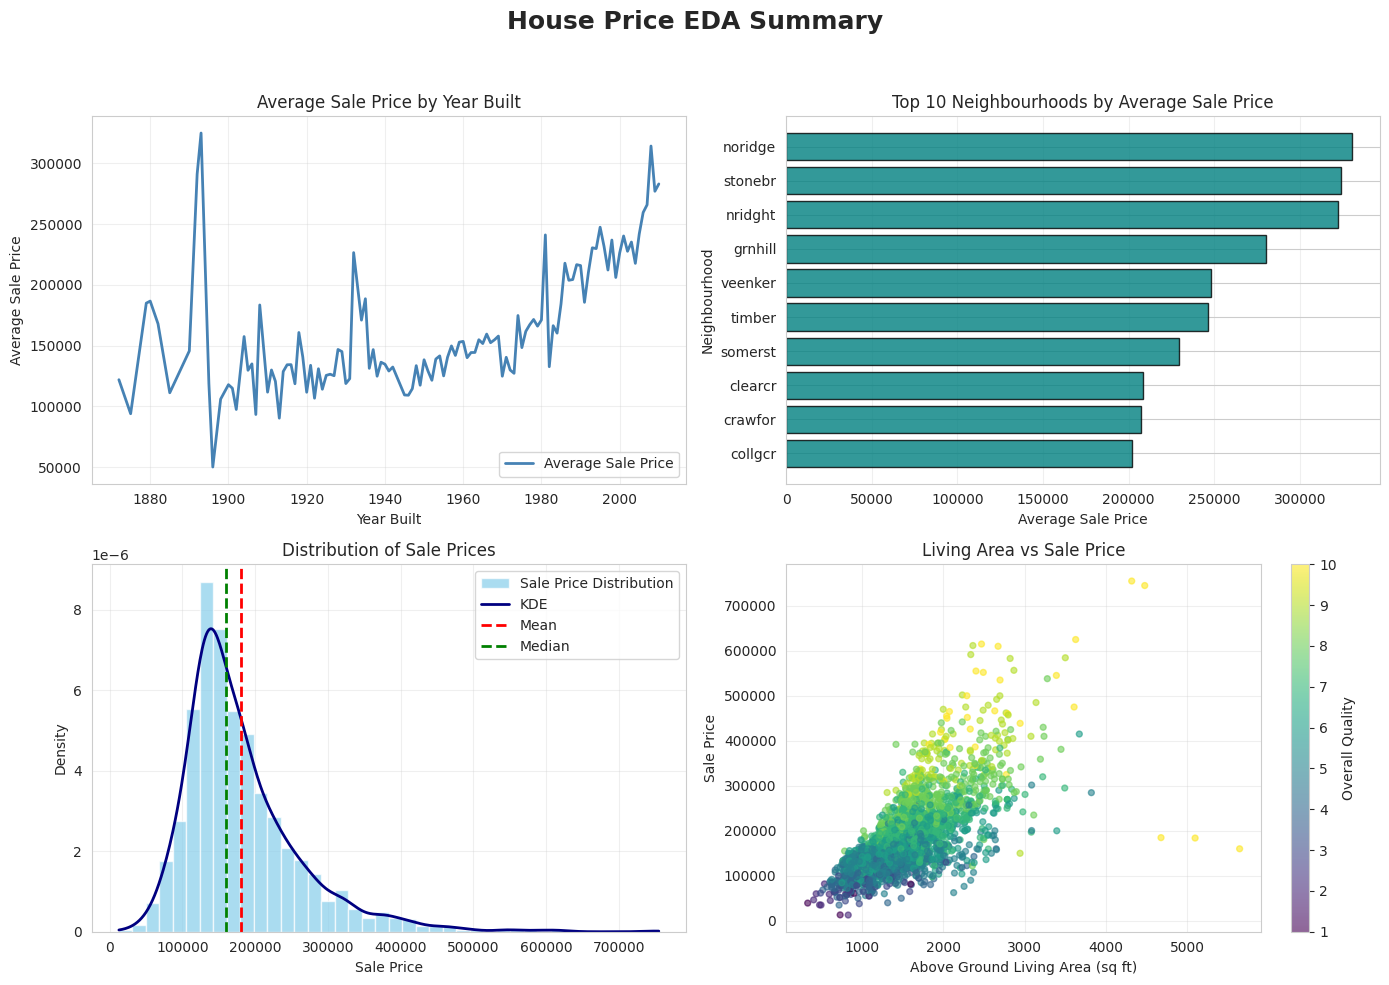

In [ ]:
from scipy.stats import gaussian_kde
data = df_clean.copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "House Price EDA Summary",
    fontsize=18,
    fontweight='bold'
)

yearly_price = data.groupby('Year Built')['SalePrice'].mean()

axes[0, 0].plot(
    yearly_price.index,
    yearly_price.values,
    color='steelblue',
    linewidth=2,
    label='Average Sale Price'
)

axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

neighbourhood_price = (
    data.groupby('Neighborhood')['SalePrice']
    .mean()
    .nlargest(10)
    .sort_values()
)

axes[0, 1].barh(
    neighbourhood_price.index,
    neighbourhood_price.values,
    color='teal',
    edgecolor='black',
    alpha=0.8
)

axes[0, 1].set_title("Top 10 Neighbourhoods by Average Sale Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighbourhood")
axes[0, 1].grid(axis='x', alpha=0.3)

prices = data['SalePrice'].dropna().to_numpy()

mean_price = np.mean(prices)
median_price = np.median(prices)

axes[1, 0].hist(
    prices,
    bins=40,
    density=True,
    color='skyblue',
    edgecolor='white',
    alpha=0.7,
    label='Sale Price Distribution'
)

x = np.linspace(prices.min(), prices.max(), 500)
kde = gaussian_kde(prices)

axes[1, 0].plot(
    x,
    kde(x),
    color='navy',
    linewidth=2,
    label='KDE'
)

axes[1, 0].axvline(
    mean_price,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Mean'
)

axes[1, 0].axvline(
    median_price,
    color='green',
    linestyle='--',
    linewidth=2,
    label='Median'
)

axes[1, 0].set_title("Distribution of Sale Prices")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


scatter = axes[1, 1].scatter(
    data['Gr Liv Area'],
    data['SalePrice'],
    c=data['Overall Qual'],
    cmap='viridis',
    alpha=0.6,
    s=18
)

axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Above Ground Living Area (sq ft)")
axes[1, 1].set_ylabel("Sale Price")

cbar = fig.colorbar(
    scatter,
    ax=axes[1, 1]
)

cbar.set_label("Overall Quality")

axes[1, 1].grid(alpha=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.95])


plt.savefig(
    "eda_dashboard.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()